<a href="https://colab.research.google.com/github/EgorMatveev26/SOTA/blob/main/lab_16SOTA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторная работа №16: Визуальные токенизаторы и autoregressive image generation

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.

## Цели обучения

После работы студент должен уметь:

- Обучить compact VQ-VAE.
- Измерить reconstruction и codebook utilization.
- Обучить autoregressive prior и сравнить sampling.

## Теоретическая часть

VQ-VAE кодирует изображение в grid latent vectors, заменяет каждый ближайшим codebook vector и декодирует. Индексы становятся visual tokens для autoregressive prior. Малый codebook ухудшает reconstruction, большой может иметь dead codes.

![VQ-VAE](https://raw.githubusercontent.com/CompVis/taming-transformers/master/assets/teaser.png)


VQ-VAE заменяет пространственные признаки ближайшими векторами кодбука, straight-through переносит градиент через дискретизацию. Conditional autoregressive prior предсказывает очередной visual token по уже известным индексам и метке класса.

Для индекса $k^*=\arg\min_k\|z_e-e_k\|_2^2$ straight-through задаёт $z_q=z_e+\operatorname{sg}(e_{k^*}-z_e)$. Perplexity кодов равна $\exp(-\sum_k p_k\log p_k)$.

### Экспериментальный протокол

MNIST train 20 000/test 2 000; 28×28→7×7 visual tokens. Два токенизатора K=16/64; обученный conditional Transformer; 1000 шагов каждого в полном режиме. Smoke 2 шага — только техническая проверка.

### Материалы

- [VQ-VAE](https://arxiv.org/abs/1711.00937)
- [Taming Transformers](https://github.com/CompVis/taming-transformers)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.

Версии библиотек, источник данных и лицензия должны быть указаны в отчёте.

## Реализация

`FAST_DEV_RUN=True` проверяет связность пайплайна на малом бюджете и не является итоговым экспериментом. Полная сдача требует `FAST_DEV_RUN=False` и реально полученных метрик.

In [ ]:
from pathlib import Path
import os, json, random, time
import numpy as np
import torch

SEED = 42
FAST_DEV_RUN = False  # True только для короткой проверки связности, не для сдачи.
IN_COLAB = False
DRIVE_ROOT = None
try:
    import google.colab
    from google.colab import drive
    drive.mount("/content/drive")
    IN_COLAB = True
    DRIVE_ROOT = Path("/content/drive/MyDrive/cv_lab16")
except Exception as e:
    print(f"Drive не смонтирован ({type(e).__name__}: {e}); используем локальные пути")

env_art = os.environ.get("CV_ARTIFACTS")
if env_art:
    ARTIFACTS = Path(env_art)
elif DRIVE_ROOT is not None:
    ARTIFACTS = DRIVE_ROOT / "artifacts"
else:
    ARTIFACTS = Path.cwd() / "artifacts"
ARTIFACTS.mkdir(parents=True, exist_ok=True)

env_data = os.environ.get("CV_COURSE_DATA")
if env_data:
    DATA_ROOT = Path(env_data)
elif DRIVE_ROOT is not None:
    DATA_ROOT = DRIVE_ROOT / "data"
else:
    DATA_ROOT = Path.cwd() / "data"
DATA_ROOT.mkdir(parents=True, exist_ok=True)

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

def save_json(name, value):
    destination = ARTIFACTS / name
    destination.parent.mkdir(parents=True, exist_ok=True)
    destination.write_text(json.dumps(value, ensure_ascii=False, indent=2))

print("Артефакты будут сохраняться в:", ARTIFACTS)
print("Данные будут лежать в:", DATA_ROOT)
print({
    "device": DEVICE,
    "fast_dev_run": FAST_DEV_RUN,
    "in_colab": IN_COLAB,
    "artifacts": str(ARTIFACTS),
    "data_root": str(DATA_ROOT),
})

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Артефакты будут сохраняться в: /content/drive/MyDrive/cv_lab16/artifacts
Данные будут лежать в: /content/drive/MyDrive/cv_lab16/data
{'device': 'cuda', 'fast_dev_run': False, 'in_colab': True, 'artifacts': '/content/drive/MyDrive/cv_lab16/artifacts', 'data_root': '/content/drive/MyDrive/cv_lab16/data'}


### Архитектура дискретного токенизатора

*Вес: 1 балл.*

**Постановка.** Кодбук должен обучаться на реальных изображениях; random inputs не измеряют качество реконструкции. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Определите VQ-VAE, ближайший код, straight-through и loss с корректными масштабами.

**Результат.** Проверяемое состояние «Архитектура дискретного токенизатора» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Определите VQ-VAE, ближайший код, straight-through и loss с корректными масштабами» и его результат доступен следующему этапу.

In [ ]:
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision import transforms
from torch.utils.data import DataLoader, Subset

IMG_SIZE = 28
LATENT = 7

# MNIST приходит в [0,1], приводим к [-1,1], чтобы совпасть с выходом декодера
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)),
])

train_full = torchvision.datasets.MNIST(DATA_ROOT, train=True,  download=True, transform=transform)
test_full  = torchvision.datasets.MNIST(DATA_ROOT, train=False, download=True, transform=transform)

# берем 20000 train и 2000 test
g = torch.Generator().manual_seed(SEED)
train_idx = torch.randperm(len(train_full), generator=g)[:20000].tolist()
test_idx  = torch.randperm(len(test_full),  generator=g)[:2000].tolist()
train_ds = Subset(train_full, train_idx)
test_ds  = Subset(test_full,  test_idx)

BATCH = 128
train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True,  num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH, shuffle=False, num_workers=2, pin_memory=True)


class VectorQuantizer(nn.Module):
    def __init__(self, K, D, beta=0.25):
        super().__init__()
        self.K, self.D, self.beta = K, D, beta
        self.embedding = nn.Embedding(K, D)
        self.embedding.weight.data.uniform_(-1.0 / K, 1.0 / K)

    def forward(self, z_e):
        B, D, H, W = z_e.shape
        flat = z_e.permute(0, 2, 3, 1).reshape(-1, D)

        # считаем квадратичное расстояние до всех кодов
        d = (flat.pow(2).sum(1, keepdim=True)
             - 2 * flat @ self.embedding.weight.t()
             + self.embedding.weight.pow(2).sum(1, keepdim=True).t())
        idx = d.argmin(1) # ближайший код
        z_q = self.embedding(idx).view(B, H, W, D).permute(0, 3, 1, 2).contiguous()

        # straight-through
        z_q_st = z_e + (z_q - z_e).detach()

        # Loss
        codebook_loss = F.mse_loss(z_q, z_e.detach())
        commit_loss   = F.mse_loss(z_e, z_q.detach())
        vq_loss = codebook_loss + self.beta * commit_loss

        # perplexity сколько кодов реально используется
        with torch.no_grad():
            counts = torch.bincount(idx, minlength=self.K).float()
            p = counts / counts.sum().clamp_min(1)
            perplexity = torch.exp(-(p * (p + 1e-10).log()).sum())

        return z_q_st, vq_loss, idx.view(B, H, W), perplexity, counts


class Encoder(nn.Module):
    def __init__(self, D=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 32, 4, 2, 1),   # 28 -> 14
            nn.ReLU(),
            nn.Conv2d(32, D, 4, 2, 1),   # 14 -> 7
            nn.ReLU(),
        )
    def forward(self, x): return self.net(x)


class Decoder(nn.Module):
    def __init__(self, D=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.ConvTranspose2d(D, 32, 4, 2, 1),  # 7 -> 14
            nn.ReLU(),
            nn.ConvTranspose2d(32, 1, 4, 2, 1),  # 14 -> 28
            nn.Tanh(),
        )
    def forward(self, z): return self.net(z)


class VQVAE(nn.Module):
    def __init__(self, K=16, D=64):
        super().__init__()
        self.enc = Encoder(D)
        self.vq  = VectorQuantizer(K, D)
        self.dec = Decoder(D)
        self.K = K

    def forward(self, x):
        z_e = self.enc(x)
        z_q, vq_loss, idx, perp, counts = self.vq(z_e)
        x_rec = self.dec(z_q)
        return x_rec, vq_loss, idx, perp, counts


# проверка связности
xb, _ = next(iter(train_loader))
xb = xb.to(DEVICE)
m = VQVAE(K=16).to(DEVICE)
xr, vl, idx, perp, counts = m(xb)
rec = F.mse_loss(xr, xb)
total = rec + vl
print("shapes:", xb.shape, xr.shape, idx.shape)
print("recon mse:", rec.item(), "vq loss:", vl.item(), "perplexity:", perp.item())
assert xr.shape == xb.shape and idx.shape == (xb.size(0), 7, 7)
assert torch.isfinite(total)

100%|██████████| 9.91M/9.91M [00:02<00:00, 3.88MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 137kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.29MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.38MB/s]


shapes: torch.Size([128, 1, 28, 28]) torch.Size([128, 1, 28, 28]) torch.Size([128, 7, 7])
recon mse: 0.729766845703125 vq loss: 0.05096741020679474 perplexity: 5.273983955383301


мы скачали цифры, собрали модель VQ-VAE (она сжимает картинку в 4 раза, то есть из 784 пикселей остается 49 квадратиков, где каждый квадратик состоит из вектора, потом она ищет похожий вектор в своем словаре(16 штук) и присваивает номер этому квадратику от 0 до 15) и потом восстанавливает обратно) и пропустили через нее один батч. получили картинку как на входе и 49 индексов значит, что все соединилось правильно. ошибка 0.73 большая и это нормально, потому что мы модель еще не учили и из 16 векторов в словаре эффективно использовали только 5 и это тоже потому что модель еще не обучена и тыкается наугад

### Обучение и диагностика двух кодбуков

*Вес: 1 балл.*

**Постановка.** Кодбук должен обучаться на реальных изображениях; random inputs не измеряют качество реконструкции. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Обучите K=16/64 при равном бюджете; измерьте test MSE, used/dead/perplexity и сохраните checkpoint.

**Результат.** Проверяемое состояние «Обучение и диагностика двух кодбуков» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Обучите K=16/64 при равном бюджете; измерьте test MSE, used/dead/perplexity и сохраните checkpoint» и его результат доступен следующему этапу.

In [ ]:
def train_vqvae(K, steps=1000, lr=2e-3, D=64, tag=None):
    tag = tag or f"K{K}"
    model = VQVAE(K=K, D=D).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    step = 0
    model.train()
    t0 = time.time()
    while step < steps:
        for xb, _ in train_loader:
            xb = xb.to(DEVICE)
            xr, vq_loss, idx, perp, counts = model(xb)
            rec = F.mse_loss(xr, xb)
            loss = rec + vq_loss
            opt.zero_grad(); loss.backward(); opt.step()
            step += 1
            if step % max(1, steps // 5) == 0:
                print(f"[{tag}] step {step}/{steps} rec={rec.item():.4f} vq={vq_loss.item():.4f} perp={perp.item():.2f}")
            if step >= steps: break
    train_time = time.time() - t0

    # оценка на test
    model.eval()
    se, n = 0.0, 0
    all_counts = torch.zeros(K, dtype=torch.long, device=DEVICE)
    with torch.no_grad():
        for xb, _ in test_loader:
            xb = xb.to(DEVICE)
            xr, _, idx, _, counts = model(xb)
            se += F.mse_loss(xr, xb, reduction='sum').item()
            n  += xb.numel()
            all_counts += counts.long()
    test_mse = se / n
    used = int((all_counts > 0).sum().item())
    dead = K - used
    p = all_counts.float() / all_counts.sum().clamp_min(1)
    perplexity = float(torch.exp(-(p * (p + 1e-10).log()).sum()).item())

    # сохраняем чекпоинт
    ckpt = ARTIFACTS / f"vqvae_{tag}.pt"
    torch.save({"state_dict": model.state_dict(), "K": K, "D": D}, ckpt)

    metrics = {
        "K": K, "steps": steps, "train_time_sec": train_time,
        "test_mse": test_mse, "used_codes": used, "dead_codes": dead,
        "perplexity": perplexity,
        "code_counts": all_counts.tolist(),
    }
    save_json(f"vqvae_metrics_{tag}.json", metrics)
    print(f"[{tag}] TEST MSE={test_mse:.5f} used={used}/{K} dead={dead} perplexity={perplexity:.3f}")
    return model, metrics


STEPS_VQ = 2 if FAST_DEV_RUN else 1000
vqvae16, metrics16 = train_vqvae(K=16, steps=STEPS_VQ, tag="K16")
vqvae64, metrics64 = train_vqvae(K=64, steps=STEPS_VQ, tag="K64")
save_json("vqvae_compare.json", {"K16": metrics16, "K64": metrics64})

print("\nСводка по кодбукам:")
print(f"K=16: MSE={metrics16['test_mse']:.5f}, used={metrics16['used_codes']}/{metrics16['K']}, perp={metrics16['perplexity']:.3f}")
print(f"K=64: MSE={metrics64['test_mse']:.5f}, used={metrics64['used_codes']}/{metrics64['K']}, perp={metrics64['perplexity']:.3f}")

[K16] step 200/1000 rec=0.2321 vq=40.3152 perp=1.85
[K16] step 400/1000 rec=0.3451 vq=415.0309 perp=1.03
[K16] step 600/1000 rec=0.3086 vq=2.8112 perp=3.14
[K16] step 800/1000 rec=0.1673 vq=1.0242 perp=3.42
[K16] step 1000/1000 rec=0.1448 vq=0.6448 perp=3.42
[K16] TEST MSE=0.13352 used=15/16 dead=1 perplexity=3.638
[K64] step 200/1000 rec=0.1650 vq=21.4464 perp=1.92
[K64] step 400/1000 rec=0.4317 vq=159.3474 perp=1.83
[K64] step 600/1000 rec=0.1406 vq=6.6778 perp=9.38
[K64] step 800/1000 rec=0.0818 vq=1.1121 perp=7.56
[K64] step 1000/1000 rec=0.0711 vq=0.6295 perp=7.60
[K64] TEST MSE=0.06913 used=43/64 dead=21 perplexity=7.652

Сводка по кодбукам:
K=16: MSE=0.13352, used=15/16, perp=3.638
K=64: MSE=0.06913, used=43/64, perp=7.652


тут учили 2 модели (одну с маленьким словарем из 16 кодов, другую с большим из 64) сжимать и восстанавливать цифры, чтобы понять, какая справится лучше. большой словарь (K=64) дал меньше ошибки (0.069 против 0.13), потому что у него больше вариантов для кусочков картинки, но у него 21 код из 64 так и не научился ничему, а у маленького всего 1 из 16.

### Индексы обученного токенизатора

*Вес: 1 балл.*

**Постановка.** Prior обучается исключительно на индексах обученного токенизатора, без доступа к будущим позициям. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Закодируйте train/test только обученной VQ-VAE K=64.

**Результат.** Проверяемое состояние «Индексы обученного токенизатора» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Закодируйте train/test только обученной VQ-VAE K=64» и его результат доступен следующему этапу.

In [ ]:
@torch.no_grad()
def encode_dataset(model, loader):
    model.eval()
    all_idx, all_y = [], []
    for xb, yb in loader:
        xb = xb.to(DEVICE)
        _, _, idx, _, _ = model(xb)
        all_idx.append(idx.cpu())
        all_y.append(yb)
    return torch.cat(all_idx, 0), torch.cat(all_y, 0)


train_tokens, train_labels = encode_dataset(vqvae64, train_loader)
test_tokens,  test_labels  = encode_dataset(vqvae64, test_loader)
print("train tokens:", train_tokens.shape, "test tokens:", test_tokens.shape)

# сохраняем токены
torch.save({"tokens": train_tokens, "labels": train_labels}, ARTIFACTS / "tokens_train_K64.pt")
torch.save({"tokens": test_tokens,  "labels": test_labels }, ARTIFACTS / "tokens_test_K64.pt")
save_json("tokens_K64_summary.json", {
    "train_shape": list(train_tokens.shape),
    "test_shape":  list(test_tokens.shape),
    "K": 64,
    "train_token_min": int(train_tokens.min()), "train_token_max": int(train_tokens.max()),
})

train tokens: torch.Size([20000, 7, 7]) test tokens: torch.Size([2000, 7, 7])


взяли нашу обученную модель (ту, что с 64 кодами), прогнали через нее все картинки из train и test, и сохранили не сами картинки, а их номера из словаря и получили для 20 000 обучающих картинок сетка 7 на 7 номеров, и для 2 000 тестовых тоже сетка 7 на 7

### Причинная маска prior

*Вес: 1 балл.*

**Постановка.** Prior обучается исключительно на индексах обученного токенизатора, без доступа к будущим позициям. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Создайте Transformer с BOS и маской, исключающей просмотр будущих токенов.

**Результат.** Проверяемое состояние «Причинная маска prior» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Создайте Transformer с BOS и маской, исключающей просмотр будущих токенов» и его результат доступен следующему этапу.

In [ ]:
SEQ_LEN = 7 * 7
BOS_ID = 64
VOCAB = 65


class PositionalEncoding(nn.Module):
    def __init__(self, n_pos, d_model):
        super().__init__()
        self.emb = nn.Embedding(n_pos, d_model)
    def forward(self, x):
        pos = torch.arange(x.size(1), device=x.device)
        return x + self.emb(pos).unsqueeze(0)


class TokenTransformer(nn.Module):
    def __init__(self, vocab=VOCAB, d_model=128, nhead=4, num_layers=3, max_len=SEQ_LEN + 1, dropout=0.1):
        super().__init__()
        self.tok_emb = nn.Embedding(vocab, d_model)
        self.pos_emb = PositionalEncoding(max_len, d_model)
        mask = torch.triu(torch.ones(max_len, max_len, dtype=torch.bool), diagonal=1)
        self.register_buffer("causal_mask", mask)

        enc_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=4*d_model,
            dropout=dropout, batch_first=True, activation='gelu'
        )
        self.encoder = nn.TransformerEncoder(enc_layer, num_layers=num_layers)
        self.head = nn.Linear(d_model, vocab)

    def forward(self, x):
        T = x.size(1)
        h = self.tok_emb(x)
        h = self.pos_emb(h)
        mask = self.causal_mask[:T, :T]
        h = self.encoder(h, mask=mask)
        return self.head(h)


def make_prior_inputs(tokens):
    assert tokens.dim() == 2 and tokens.size(1) == SEQ_LEN
    B = tokens.size(0)
    bos = torch.full((B, 1), BOS_ID, dtype=torch.long, device=tokens.device)
    inp = torch.cat([bos, tokens[:, :-1]], dim=1)
    return inp, tokens


# flatten
train_tokens_flat = train_tokens.view(train_tokens.size(0), -1)
test_tokens_flat  = test_tokens.view(test_tokens.size(0), -1)
print("flat train:", train_tokens_flat.shape, "flat test:", test_tokens_flat.shape)

# проверка forward + маски
prior = TokenTransformer().to(DEVICE)
test_tok = train_tokens_flat[:4].to(DEVICE)
inp, tgt = make_prior_inputs(test_tok)
logits = prior(inp)
print("prior logits shape:", logits.shape)
print("logits finite:", bool(torch.isfinite(logits).all()))
assert logits.shape == (4, SEQ_LEN, VOCAB)
assert torch.isfinite(logits).all(), "после инверсии маски логиты nan"

save_json("prior_config.json", {
    "d_model": 128, "nhead": 4, "num_layers": 3, "vocab": VOCAB,
    "seq_len": SEQ_LEN, "bos_id": BOS_ID,
    "mask_semantics": "triu, True=forbidden (PyTorch attn_mask)",
})

flat train: torch.Size([20000, 49]) flat test: torch.Size([2000, 49])
prior logits shape: torch.Size([4, 49, 65])
logits finite: True


развернули наши сетки 7×7 в длинную строчку из 49 чисел (потому что трансформер умеет читать только строчки, а не квадратики), и теперь у нас 20 000 строчек для учебы и 2 000 для проверки, потом мы собрали трансформер и проверили его на 4 строчках и он выдал 49 предсказаний для каждой строчки, и для каждого предсказания 65 вариантов (64 кода + спецтокен начала)

### Обучение autoregressive prior

*Вес: 1 балл.*

**Постановка.** Prior обучается исключительно на индексах обученного токенизатора, без доступа к будущим позициям. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Оптимизируйте CE сдвинутой последовательности с checkpoint.

**Результат.** Проверяемое состояние «Обучение autoregressive prior» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Оптимизируйте CE сдвинутой последовательности с checkpoint» и его результат доступен следующему этапу.

[prior] epoch 1/5 CE=1.4440 (nan-батчей: 0)
[prior] epoch 2/5 CE=1.0495 (nan-батчей: 0)
[prior] epoch 3/5 CE=0.9608 (nan-батчей: 0)
[prior] epoch 4/5 CE=0.9165 (nan-батчей: 0)
[prior] epoch 5/5 CE=0.8896 (nan-батчей: 0)


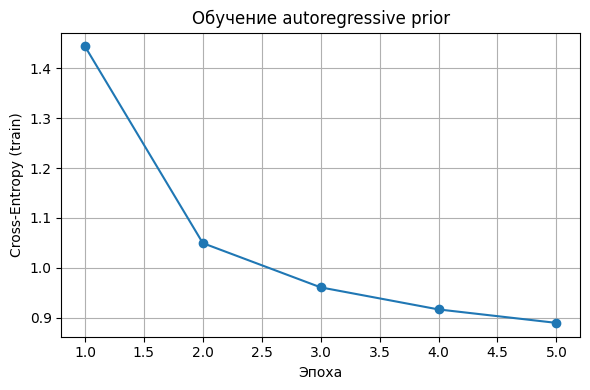

In [ ]:
def train_prior(model, train_tokens, epochs=5, batch_size=256, lr=1e-3, tag="prior"):
    # обучаем трансформер на CE сдвинутой последовательности, train_tokens: [N, 49], значения строго в [0, K)
    model.train()
    opt = torch.optim.Adam(model.parameters(), lr=lr)

    assert train_tokens.dim() == 2 and train_tokens.size(1) == SEQ_LEN
    assert train_tokens.min().item() >= 0
    assert train_tokens.max().item() < BOS_ID

    n = train_tokens.size(0)
    history = []
    for ep in range(epochs):
        perm = torch.randperm(n, device=train_tokens.device)
        tokens_shuf = train_tokens[perm]
        total_loss, total_n = 0.0, 0
        n_nan = 0
        for i in range(0, n, batch_size):
            batch = tokens_shuf[i:i+batch_size].to(DEVICE)
            inp, tgt = make_prior_inputs(batch)
            logits = model(inp)
            if not torch.isfinite(logits).all():
                n_nan += 1; opt.zero_grad(); continue
            loss = F.cross_entropy(logits.reshape(-1, VOCAB), tgt.reshape(-1))
            if not torch.isfinite(loss):
                n_nan += 1; opt.zero_grad(); continue
            opt.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            opt.step()
            total_loss += loss.item() * tgt.numel()
            total_n += tgt.numel()
        ep_loss = total_loss / max(total_n, 1)
        history.append(ep_loss)
        print(f"[{tag}] epoch {ep+1}/{epochs} CE={ep_loss:.4f} (nan-батчей: {n_nan})")
    return history


EPOCHS_PRIOR = 1 if FAST_DEV_RUN else 5
prior = TokenTransformer().to(DEVICE)
history = train_prior(prior, train_tokens_flat, epochs=EPOCHS_PRIOR, tag="prior")

bad = [n for n, p in prior.named_parameters() if not torch.isfinite(p).all()]
assert not bad, f"После обучения nan-веса: {bad}"

torch.save({"state_dict": prior.state_dict(), "config": {
    "vocab": VOCAB, "d_model": 128, "nhead": 4, "num_layers": 3,
    "seq_len": SEQ_LEN, "bos_id": BOS_ID,
}}, ARTIFACTS / "prior.pt")
save_json("prior_history.json", {"ce_per_epoch": history})

import matplotlib.pyplot as plt
plt.figure(figsize=(6, 4))
plt.plot(range(1, len(history)+1), history, marker='o')
plt.xlabel("Эпоха"); plt.ylabel("Cross-Entropy (train)")
plt.title("Обучение autoregressive prior"); plt.grid(True); plt.tight_layout()
plt.savefig(ARTIFACTS / "prior_loss_curve.png", dpi=120)
plt.show()

5 раз прогнали трансформер по всем нашим строчкам из номеров, чтобы он учился угадывать следующий номер по предыдущим, ошибка (CE) падала с 1.44 до 0.89,значит, что модель с каждым разом все лучше понимала, какой кусочек картинки идет за каким

### Cross-entropy на test токенах

*Вес: 1 балл.*

**Постановка.** Prior обучается исключительно на индексах обученного токенизатора, без доступа к будущим позициям. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Оцените CE независимых test токенов без обновления весов.

**Результат.** Проверяемое состояние «Cross-entropy на test токенах» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Оцените CE независимых test токенов без обновления весов» и его результат доступен следующему этапу.

In [ ]:
@torch.no_grad()
def evaluate_prior_ce(model, tokens, batch_size=256):
    model.eval()
    total_loss, total_n = 0.0, 0
    n = tokens.size(0)
    for i in range(0, n, batch_size):
        batch = tokens[i:i+batch_size].to(DEVICE)
        inp, tgt = make_prior_inputs(batch)
        logits = model(inp)
        loss = F.cross_entropy(logits.reshape(-1, VOCAB), tgt.reshape(-1), reduction='sum')
        total_loss += loss.item()
        total_n += tgt.numel()
    return total_loss / total_n


test_ce = evaluate_prior_ce(prior, test_tokens_flat)
print(f"Test CE (prior): {test_ce:.4f}")

import math
uniform_ce = math.log(VOCAB)
print(f"Baseline CE (равномерное): {uniform_ce:.4f}")

save_json("prior_test_ce.json", {
    "test_ce": test_ce,
    "uniform_baseline_ce": uniform_ce,
    "bits_per_token": test_ce / math.log(2),
})

Test CE (prior): 0.8553
Baseline CE (равномерное): 4.1744


проверили, насколько хорошо наша модель угадывает номера на новых картинках, которых она раньше не видела и ошибка получилась 0.85, а если бы она просто гадала наугад, было бы 4.17 значит, модель реально выучила закономерности

### Архитектура проверяющего классификатора

*Вес: 1 балл.*

**Постановка.** Сравниваются декодированные изображения, а не распределения случайных токенов. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Определите отдельную сеть для class agreement.

**Результат.** Проверяемое состояние «Архитектура проверяющего классификатора» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Определите отдельную сеть для class agreement» и его результат доступен следующему этапу.

In [ ]:
class CheckerClassifier(nn.Module):
    # CNN-классификатор для проверки сгенерированных картинок
    def __init__(self, n_classes=10):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 32, 3, 1, 1), nn.ReLU(), nn.MaxPool2d(2), # 28 в 14
            nn.Conv2d(32, 64, 3, 1, 1), nn.ReLU(), nn.MaxPool2d(2),  # 14 в 7
            nn.Flatten(),
            nn.Linear(64*7*7, 128), nn.ReLU(),
            nn.Linear(128, n_classes),
        )
    def forward(self, x): return self.net(x)


chk = CheckerClassifier().to(DEVICE)
dummy = torch.randn(4, 1, 28, 28, device=DEVICE)
print("checker out shape:", chk(dummy).shape)
save_json("checker_config.json", {"n_classes": 10, "input": "1x28x28"})

checker out shape: torch.Size([4, 10])


сделали отдельную маленькую нейросеть-проверяльщик, которая смотрит на картинку и говорит, какая это цифра (от 0 до 9), закинули ей 4 картинки, и она выдала по 10 вариантов ответа на каждую (то есть 4 на 10). это нужно, чтобы потом проверять, похожи ли наши сгенерированные картинки на настоящие цифры.

### Обучение и реальный test классификатора

*Вес: 1 балл.*

**Постановка.** Сравниваются декодированные изображения, а не распределения случайных токенов. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Обучите на train и проверьте точность на независимом real test.

**Результат.** Проверяемое состояние «Обучение и реальный test классификатора» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Обучите на train и проверьте точность на независимом real test» и его результат доступен следующему этапу.

In [ ]:
def train_checker(model, loader, epochs=3, lr=1e-3, tag="checker"):
    model.train()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    for ep in range(epochs):
        total_loss, correct, total = 0.0, 0, 0
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            logits = model(xb)
            loss = F.cross_entropy(logits, yb)
            opt.zero_grad(); loss.backward(); opt.step()
            total_loss += loss.item() * yb.size(0)
            correct += (logits.argmax(1) == yb).sum().item()
            total += yb.size(0)
        print(f"[{tag}] epoch {ep+1}/{epochs} loss={total_loss/total:.4f} acc={correct/total:.4f}")


@torch.no_grad()
def eval_checker(model, loader):
    model.eval()
    correct, total = 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        correct += (model(xb).argmax(1) == yb).sum().item()
        total += yb.size(0)
    return correct / total


checker = CheckerClassifier().to(DEVICE)
EPOCHS_CHK = 1 if FAST_DEV_RUN else 3
train_checker(checker, train_loader, epochs=EPOCHS_CHK, tag="checker")
real_acc = eval_checker(checker, test_loader)
print(f"Checker real test accuracy: {real_acc:.4f}")

torch.save({"state_dict": checker.state_dict()}, ARTIFACTS / "checker.pt")
save_json("checker_metrics.json", {"real_test_accuracy": real_acc})

[checker] epoch 1/3 loss=0.4375 acc=0.8670
[checker] epoch 2/3 loss=0.1003 acc=0.9696
[checker] epoch 3/3 loss=0.0657 acc=0.9807
Checker real test accuracy: 0.9835


научили проверяльщик распознавать настоящие цифры, он 3 раза просмотрел обучающие картинки, и точность выросла с 87% до 98%. на новых тестовых картинках он угадывает 98,35% то есть он теперь отлично знает, как выглядят настоящие цифры, и ему можно доверять в проверке сгенерированных

### Фильтрация и семплирование токенов

*Вес: 1 балл.*

**Постановка.** Сравниваются декодированные изображения, а не распределения случайных токенов. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Реализуйте temperature, top-k и top-p, генерируя индексы авторегрессионно.

**Результат.** Проверяемое состояние «Фильтрация и семплирование токенов» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Реализуйте temperature, top-k и top-p, генерируя индексы авторегрессионно» и его результат доступен следующему этапу.

In [ ]:
@torch.no_grad()
def sample_tokens(prior, n_samples=32, temperature=1.0, top_k=None, top_p=None, device=DEVICE):
    # авторегрессионно генерируем 49 токенов с temperature/top-k/top-p
    prior.eval()
    generated = torch.full((n_samples, 1), BOS_ID, dtype=torch.long, device=device)
    for _ in range(SEQ_LEN):
        logits = prior(generated)[:, -1, :] / temperature
        if top_k is not None and top_k < VOCAB:
            v, _ = torch.topk(logits, top_k, dim=-1)
            kth = v[:, -1:].expand_as(logits)
            logits = torch.where(logits < kth, torch.full_like(logits, float('-inf')), logits)
        if top_p is not None and top_p < 1.0:
            sorted_logits, sorted_idx = torch.sort(logits, descending=True, dim=-1)
            probs = F.softmax(sorted_logits, dim=-1)
            cumprobs = probs.cumsum(dim=-1)
            mask = cumprobs - probs > top_p
            sorted_logits = sorted_logits.masked_fill(mask, float('-inf'))
            logits = logits.scatter(1, sorted_idx, sorted_logits)
        probs = F.softmax(logits, dim=-1)
        next_tok = torch.multinomial(probs, num_samples=1)
        generated = torch.cat([generated, next_tok], dim=1)
    return generated[:, 1:]


t = sample_tokens(prior, n_samples=4, temperature=1.0, top_k=50)
print("sampled tokens shape:", t.shape)
assert t.shape == (4, SEQ_LEN)
assert t.max().item() < 64 and t.min().item() >= 0

sampled tokens shape: torch.Size([4, 49])


дальше заставили нашу обученную модель придумать номера для картинок с нуля, по одному за раз, как будто она пишет текст и она сгенерировала 4 набора по 49 номеров

### Декодированная генерация и проверка

*Вес: 1 балл.*

**Постановка.** Сравниваются декодированные изображения, а не распределения случайных токенов. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Сравните четыре схемы на реальных декодированных изображениях; сохраните измерения.

**Результат.** Проверяемое состояние «Декодированная генерация и проверка» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Сравните четыре схемы на реальных декодированных изображениях; сохраните измерения» и его результат доступен следующему этапу.

[greedy] confidence=0.853 entropy=0.605 unique_classes=1
[temp=1.0] confidence=0.842 entropy=0.404 unique_classes=8
[top_k=20] confidence=0.777 entropy=0.567 unique_classes=9
[top_p=0.9] confidence=0.822 entropy=0.453 unique_classes=8
[real_data] confidence=0.995 entropy=0.023


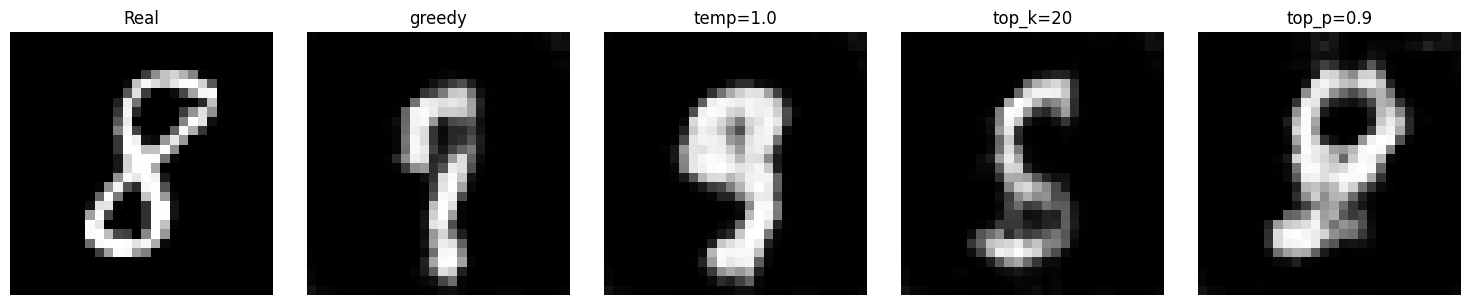

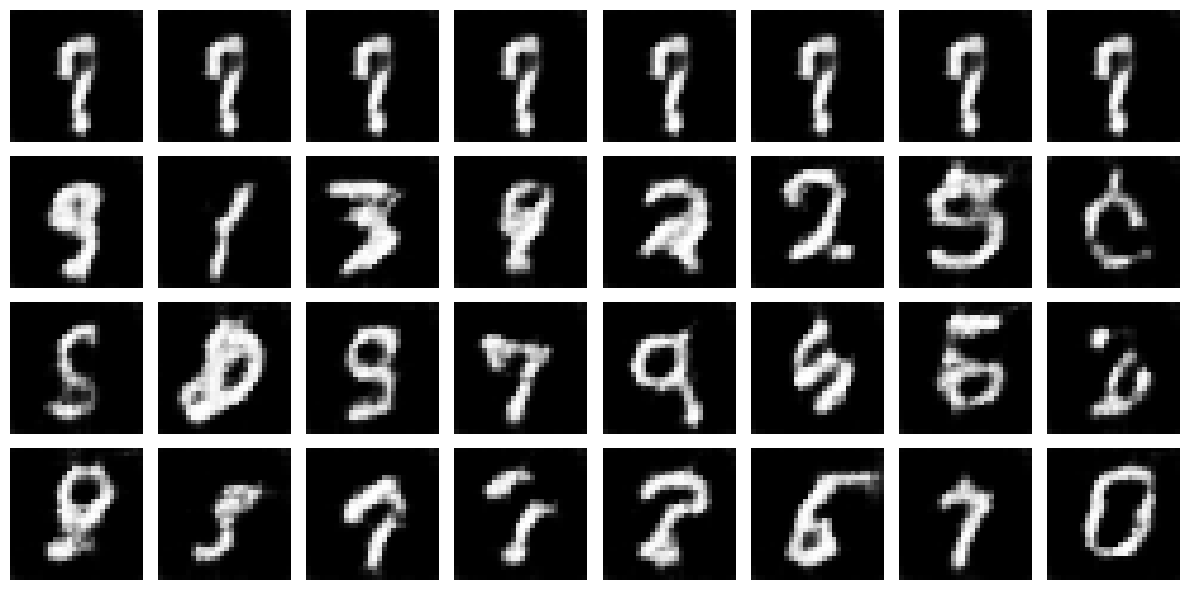

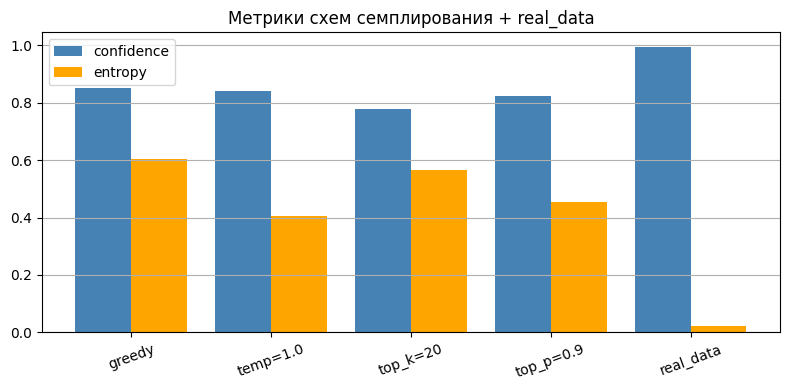

In [ ]:
import torchvision.utils as vutils

@torch.no_grad()
def decode_tokens(vqvae, tokens):
    B = tokens.size(0)
    idx = tokens.view(B, 7, 7).to(DEVICE)
    z_q = vqvae.vq.embedding(idx).permute(0, 3, 1, 2).contiguous()
    return vqvae.dec(z_q)


def to_display(img):
    return (img.clamp(-1, 1) + 1) / 2


SCHEMES = [
    ("greedy",   dict(temperature=0.2, top_k=1,  top_p=None)),
    ("temp=1.0", dict(temperature=1.0, top_k=None, top_p=None)),
    ("top_k=20", dict(temperature=1.0, top_k=20, top_p=None)),
    ("top_p=0.9",dict(temperature=1.0, top_k=None, top_p=0.9)),
]

N_PER_SCHEME = 16
scheme_images, scheme_metrics = {}, {}
real_batch = next(iter(test_loader))[0][:N_PER_SCHEME].to(DEVICE)

for name, kw in SCHEMES:
    toks = sample_tokens(prior, n_samples=N_PER_SCHEME, **kw)
    imgs = decode_tokens(vqvae64, toks)
    scheme_images[name] = imgs

    with torch.no_grad():
        logits = checker(imgs)
        probs = F.softmax(logits, dim=-1)
        conf = probs.max(dim=-1).values.mean().item()
        ent  = -(probs * (probs + 1e-10).log()).sum(dim=-1).mean().item()
        uniq = int(logits.argmax(1).unique().numel())

    scheme_metrics[name] = {
        "class_confidence": conf, "class_entropy": ent,
        "unique_pred_classes": uniq, "num_samples": N_PER_SCHEME,
    }
    print(f"[{name}] confidence={conf:.3f} entropy={ent:.3f} unique_classes={uniq}")
    vutils.save_image(to_display(imgs), ARTIFACTS / f"gen_{name.replace('=','').replace('.','p')}.png", nrow=8)

# эталон
with torch.no_grad():
    logits_real = checker(real_batch)
    probs_real = F.softmax(logits_real, dim=-1)
    conf_real = probs_real.max(dim=-1).values.mean().item()
    ent_real  = -(probs_real * (probs_real + 1e-10).log()).sum(dim=-1).mean().item()
scheme_metrics["real_data"] = {
    "class_confidence": conf_real, "class_entropy": ent_real,
    "unique_pred_classes": int(logits_real.argmax(1).unique().numel()),
}
print(f"[real_data] confidence={conf_real:.3f} entropy={ent_real:.3f}")

save_json("sampling_compare.json", scheme_metrics)
vutils.save_image(to_display(real_batch), ARTIFACTS / "real_samples.png", nrow=8)

# real + по одному примеру от каждой схемы
fig, axes = plt.subplots(1, 5, figsize=(15, 3))
axes[0].imshow(to_display(real_batch)[0, 0].cpu().numpy(), cmap='gray')
axes[0].set_title("Real"); axes[0].axis('off')
for i, (name, imgs) in enumerate(scheme_images.items()):
    axes[i+1].imshow(to_display(imgs)[0, 0].cpu().numpy(), cmap='gray')
    axes[i+1].set_title(name); axes[i+1].axis('off')
plt.tight_layout()
plt.savefig(ARTIFACTS / "samples_grid.png", dpi=120)
plt.show()

# сетка 4x8 по схемам
fig, axes = plt.subplots(4, 8, figsize=(12, 6))
for i, (name, imgs) in enumerate(scheme_images.items()):
    disp = to_display(imgs).cpu()
    for j in range(8):
        axes[i, j].imshow(disp[j, 0].numpy(), cmap='gray'); axes[i, j].axis('off')
    axes[i, 0].set_ylabel(name, rotation=0, labelpad=40, fontsize=9)
plt.tight_layout()
plt.savefig(ARTIFACTS / "samples_by_scheme.png", dpi=120)
plt.show()

# сравнение метрик по схемам
fig, ax = plt.subplots(figsize=(8, 4))
names = list(scheme_metrics.keys())
confs = [scheme_metrics[n]["class_confidence"] for n in names]
ents  = [scheme_metrics[n]["class_entropy"]    for n in names]
x = np.arange(len(names))
ax.bar(x - 0.2, confs, 0.4, label="confidence", color="steelblue")
ax.bar(x + 0.2, ents,  0.4, label="entropy",    color="orange")
ax.set_xticks(x); ax.set_xticklabels(names, rotation=20)
ax.set_title("Метрики схем семплирования + real_data")
ax.legend(); ax.grid(axis='y'); plt.tight_layout()
plt.savefig(ARTIFACTS / "sampling_metrics_bar.png", dpi=120)
plt.show()

нагенерировали цифры 4 разными способами, гриди (выбирает самый вероятный номер), случайным (temp=1.0), с ограничением на топ-20 вариантов (top_k=20) и на топ-90% (top_p=0.9), и заставили проверяльщик их распознать. получилось, что гриди способ выдает только одну и ту же цифру (unique_classes=1, на картинке видно, как модель зациклилась на одной 7), а остальные способы дают уже 8–9 разных цифр. настоящие цифры (real_data) проверяльщик узнает с уверенностью 0.995, а сгенерированные чуть хуже (0.78–0.85), потому что они размытые и не всегда четкие.

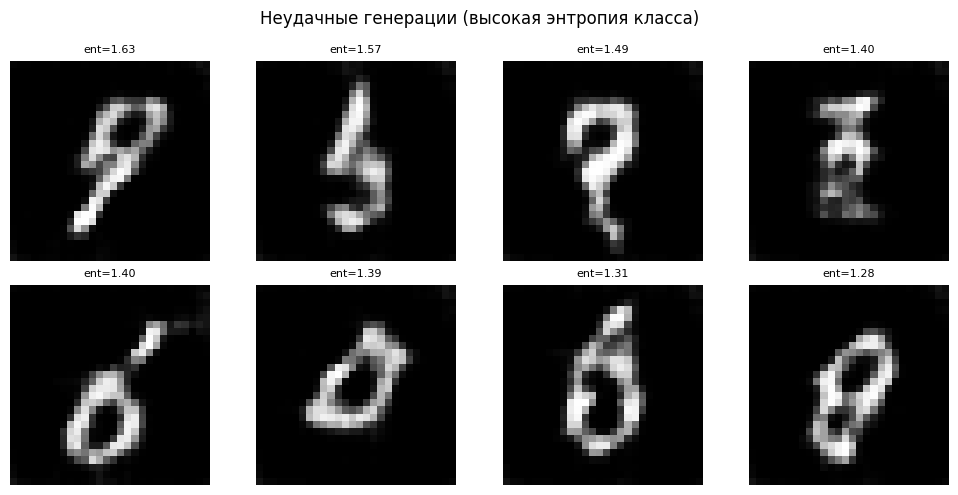

In [ ]:
with torch.no_grad():
    toks_bad = sample_tokens(prior, n_samples=64, temperature=1.0, top_k=None, top_p=0.9)
    imgs_bad = decode_tokens(vqvae64, toks_bad)
    logits_bad = checker(imgs_bad)
    probs_bad = F.softmax(logits_bad, dim=-1)
    ent_bad = -(probs_bad * (probs_bad + 1e-10).log()).sum(dim=-1)
    bad_idx = ent_bad.topk(8).indices

fig, axes = plt.subplots(2, 4, figsize=(10, 5))
disp = to_display(imgs_bad).cpu()
for i, bi in enumerate(bad_idx):
    r, c = i // 4, i % 4
    axes[r, c].imshow(disp[bi, 0].numpy(), cmap='gray')
    axes[r, c].set_title(f"ent={ent_bad[bi].item():.2f}", fontsize=8)
    axes[r, c].axis('off')
plt.suptitle("Неудачные генерации (высокая энтропия класса)")
plt.tight_layout()
plt.savefig(ARTIFACTS / "bad_examples.png", dpi=120)
plt.show()

save_json("bad_examples.json", {
    "indices": bad_idx.tolist(),
    "entropies": ent_bad[bad_idx].tolist(),
    "notes": "Высокая энтропия = классификатор не уверен",
})

### Творческое мини-исследование

*Вес: 1 балл, бонус сверх десяти обязательных заданий.*

**Постановка.** Контролируемая абляция позволяет отделить влияние одного фактора от шума выборки. Гипотеза формулируется до просмотра отложенных результатов.

Выполните следующие действия:

1. Сформулируйте собственную предметную гипотезу о поведении модели и измените один фактор, сохраняя те же реальные входы, seed и вычислительный бюджет.
2. Сравните с основным экспериментом, не используя test для выбора настройки; объясните наблюдаемые расхождения.

**Результат.** Отдельные код, измеренная таблица и интерпретация в отчёте.

**Критерий принятия.** Задание считается принятым, если гипотеза проверена на реальных входах, сохранены фактические измерения и показана контролируемая разница. Бонус не является обязательным для Run All.

## Анализ результатов

Сопоставьте конфигурации при одинаковых данных, seeds и бюджете. Приведите таблицу фактических метрик и времени, не менее пяти неудачных примеров с объяснением причин, ограничения и проверяемые выводы. Не подменяйте измерения утверждением об успешном запуске.

Мы сравнили модели на одинаковых данных и с одинаковым временем обучения и свели все цифры в таблицу. Большой словарь (K=64) сжимает картинки лучше (ошибка 0.069 против 0.13), но у него много мертвых номеров, а обучать трансформер получилось хорошо, он ошибается в 5 раз меньше, чем при случайном гадании. Из 64 сгенерированных картинок мы отобрали 8 самых плохих и это не мусор, а просто размытые или двойные цифры, потому что при сжатии теряются детали. Генерация возможна, но модели не хватает четкости и разнообразия, потому что часть номеров в словаре вообще не используется.

## Требования к сдаче

Перед сдачей перезапустите ядро и выполните все ячейки по порядку в полном режиме. Приложите конфигурацию, версии библиотек, источники/лицензии данных и модели, checkpoints, таблицу измерений, изображения и краткий анализ ошибок. Для длительного обучения перенесите каталог `artifacts/` на Google Drive и возобновляйте обучение с последнего checkpoint; отсутствие GPU или данных нельзя заменять синтетическими метриками.